# Ejercicio 2: Predicción de niveles de glucosa en sangre

**Laboratorio 1 – Minería de Datos** · Regresión lineal múltiple siguiendo la metodología **CRISP-DM**

Dataset: `data/glucosa_data.csv` · Variable dependiente: `Nivel_Glucosa`

**Contenido**
1. Comprensión del negocio
2. Comprensión de los datos (EDA)
3. Preparación de los datos
4. Modelado
5. Evaluación
6. Despliegue: exportación del modelo
7. Conclusiones

## 1. Comprensión del negocio

**Contexto.** Un nivel alto de glucosa en sangre es un factor de riesgo de diabetes. Identificar qué características de un paciente se asocian con la glucosa ayuda a enfocar la prevención.

**Objetivo de minería de datos.** Construir un modelo de **regresión lineal múltiple** que prediga `Nivel_Glucosa` a partir de:

| Variable | Descripción | Rol |
|---|---|---|
| `Edad` | Edad del paciente (años) | Independiente |
| `IMC` | Índice de masa corporal | Independiente |
| `Actividad_Fisica` | Horas semanales de ejercicio | Independiente |
| `Nivel_Glucosa` | Glucosa en sangre (mg/dL) | **Dependiente** |

**Preguntas a responder.**
1. ¿Cómo afecta cada variable a la glucosa y qué tan importante es cada una?
2. ¿Qué tan bien predice el modelo? (MSE y R²)
3. **¿Qué variable tiene mayor impacto en el nivel de glucosa?**

**Criterio de éxito.** Un modelo con coeficientes interpretables y un R² aceptable en datos de prueba.

### Librerías y configuración

In [1]:
import json
import pickle
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Rutas del proyecto (funciona ejecutando desde notebooks/ o desde la raíz)
BASE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = BASE / "data"
FIGURAS = BASE / "informe" / "figuras"
MODELOS = BASE / "modelos"
FIGURAS.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

# Configuración del ejercicio
NOMBRE = "glucosa"
OBJETIVO = "Nivel_Glucosa"
VARIABLES = ['Edad', 'IMC', 'Actividad_Fisica']
ETIQUETAS = {'Edad': 'Edad (años)', 'IMC': 'Índice de masa corporal (kg/m²)', 'Actividad_Fisica': 'Actividad física (horas por semana)', 'Nivel_Glucosa': 'Nivel de glucosa (mg/dL)'}
UNIDAD_Y = "mg/dL"
SEMILLA = 42

# Estilo de las gráficas
AZUL, NARANJA, AQUA, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
TEXTO, TEXTO_SEC, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_SEC,
    "axes.titlecolor": TEXTO, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC, "ytick.color": TEXTO_SEC,
    "legend.frameon": False, "font.size": 10, "savefig.dpi": 150,
})
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("azul_rojo", [AZUL, "#f0efec", ROJO])


def guardar(fig, nombre):
    """Guarda la figura como PNG en informe/figuras/."""
    ruta = FIGURAS / f"{NOMBRE}_{nombre}.png"
    fig.savefig(ruta, bbox_inches="tight")
    print("Figura guardada:", ruta.relative_to(BASE))


def fmt_p(p):
    """Muestra un p-valor de forma legible."""
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. Comprensión de los datos (EDA)

### 2.1 Carga y estructura

In [2]:
df = pd.read_csv(DATA / f"{NOMBRE}_data.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (2000, 4)


,Edad,IMC,Actividad_Fisica,Nivel_Glucosa
0,42,13.4664,1,141.8403
1,67,23.4556,1,171.9374
2,71,25.7652,8,155.5042
3,48,24.0795,2,115.8652
4,35,24.4266,7,115.6987


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Edad              2000 non-null   int64  
 1   IMC               2000 non-null   float64
 2   Actividad_Fisica  2000 non-null   int64  
 3   Nivel_Glucosa     2000 non-null   float64
dtypes: float64(2), int64(2)
memory usage: 62.6 KB


### 2.2 Estadísticas descriptivas y rangos

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Edad,"2,000.0000",49.1570,17.5445,20.0000,34.0000,50.0000,64.0000,79.0000
IMC,"2,000.0000",24.9633,3.9836,10.5867,22.3445,25.0287,27.7511,39.4302
Actividad_Fisica,"2,000.0000",4.6645,2.9122,0.0000,2.0000,5.0000,7.0000,9.0000
Nivel_Glucosa,"2,000.0000",139.6301,27.3429,43.4159,119.0676,139.9673,159.2085,227.5607


### 2.3 Calidad de los datos: nulos, duplicados y atípicos

In [5]:
print("Valores nulos por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
Edad                0
IMC                 0
Actividad_Fisica    0
Nivel_Glucosa       0

Filas duplicadas: 0


In [6]:
# Valores atípicos con la regla del rango intercuartílico (IQR)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = ((df < lim_inf) | (df > lim_sup)).sum()
pd.DataFrame({
    "limite_inferior": lim_inf, "limite_superior": lim_sup,
    "minimo": df.min(), "maximo": df.max(),
    "n_atipicos": atipicos, "porcentaje": 100 * atipicos / len(df),
})

,limite_inferior,limite_superior,minimo,maximo,n_atipicos,porcentaje
Edad,-11.0000,109.0000,20.0000,79.0000,0,0.0000
IMC,14.2347,35.8609,10.5867,39.4302,16,0.8000
Actividad_Fisica,-5.5000,14.5000,0.0000,9.0000,0,0.0000
Nivel_Glucosa,58.8562,219.4198,43.4159,227.5607,3,0.1500


**Hallazgos de la revisión de calidad**

- El dataset tiene **2 000 filas y 4 columnas**, todas numéricas. `Edad` (20 a 79 años) y `Actividad_Fisica` (0 a 9 horas) son enteras.
- **No hay valores nulos ni filas duplicadas.**
- Con la regla IQR aparecen **16 valores atípicos en `IMC`** (0.8 %) y **3 en `Nivel_Glucosa`** (0.15 %). El IMC mínimo es 10.59 y la glucosa mínima 43.4 mg/dL: son valores extremos pero no imposibles, y son muy pocos. **Se conservan**, porque eliminarlos no está justificado como error y casi no cambiaría el modelo.
- La glucosa tiene media de 139.6 mg/dL y va de 43.4 a 227.6.

### 2.4 Distribución de las variables

Figura guardada: informe/figuras/glucosa_distribuciones.png


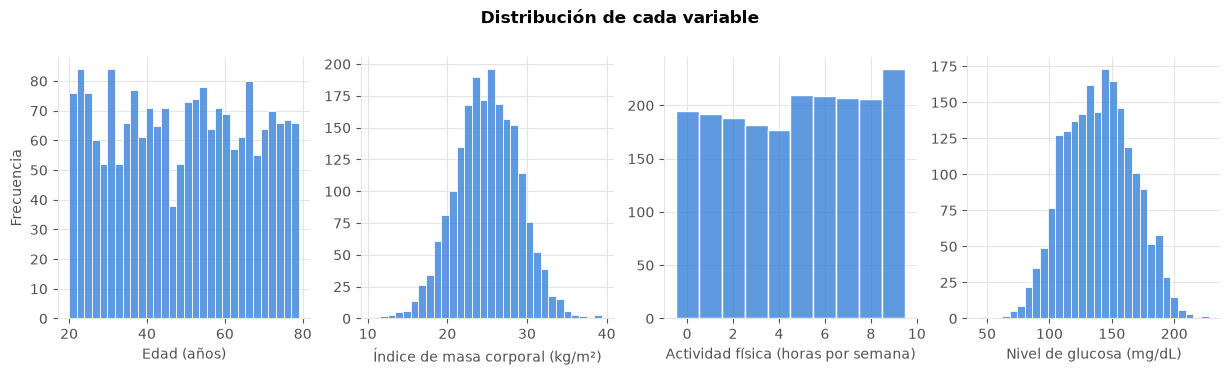

In [7]:
fig, ejes = plt.subplots(1, len(df.columns), figsize=(15, 3.4))
for ax, col in zip(ejes, df.columns):
    discreta = df[col].nunique() < 30
    sns.histplot(df[col], ax=ax, color=AZUL, edgecolor="white", discrete=discreta, bins="auto" if discreta else 30)
    ax.set_xlabel(ETIQUETAS[col])
    ax.set_ylabel("Frecuencia" if ax is ejes[0] else "")
fig.suptitle("Distribución de cada variable", fontweight="bold", y=1.02)
guardar(fig, "distribuciones")
plt.show()

### 2.5 Matriz de correlación

Figura guardada: informe/figuras/glucosa_correlacion.png


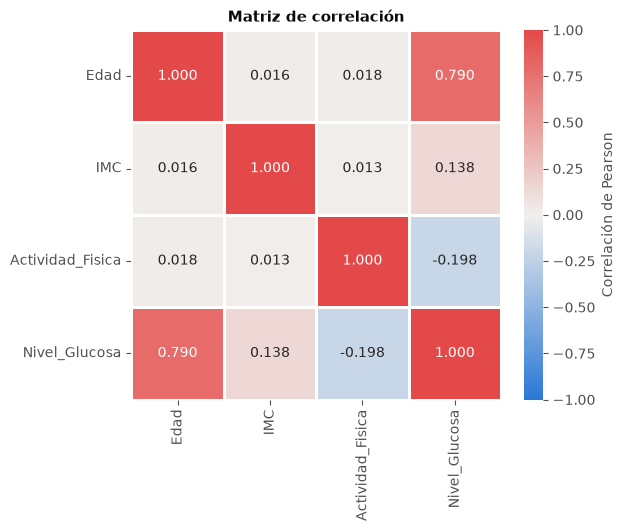

,Correlación con Nivel_Glucosa
Edad,0.7898
IMC,0.1383
Actividad_Fisica,-0.1984


In [8]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt=".3f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", square=True, ax=ax,
            cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Matriz de correlación")
ax.grid(False)
guardar(fig, "correlacion")
plt.show()

corr[OBJETIVO].drop(OBJETIVO).to_frame("Correlación con " + OBJETIVO)

**Lectura de la matriz de correlación**

- `Edad` es la variable más relacionada con la glucosa (**r = 0.790**, positiva y fuerte).
- `Actividad_Fisica` tiene correlación **negativa** (−0.198): más ejercicio, menos glucosa.
- `IMC` tiene una correlación positiva débil (0.138).
- Las variables independientes no se relacionan entre sí (correlaciones menores a 0.02), por lo que **no hay multicolinealidad** y cada coeficiente se puede interpretar por separado.

### 2.6 Relación de cada variable independiente con `Nivel_Glucosa`

Figura guardada: informe/figuras/glucosa_dispersion.png


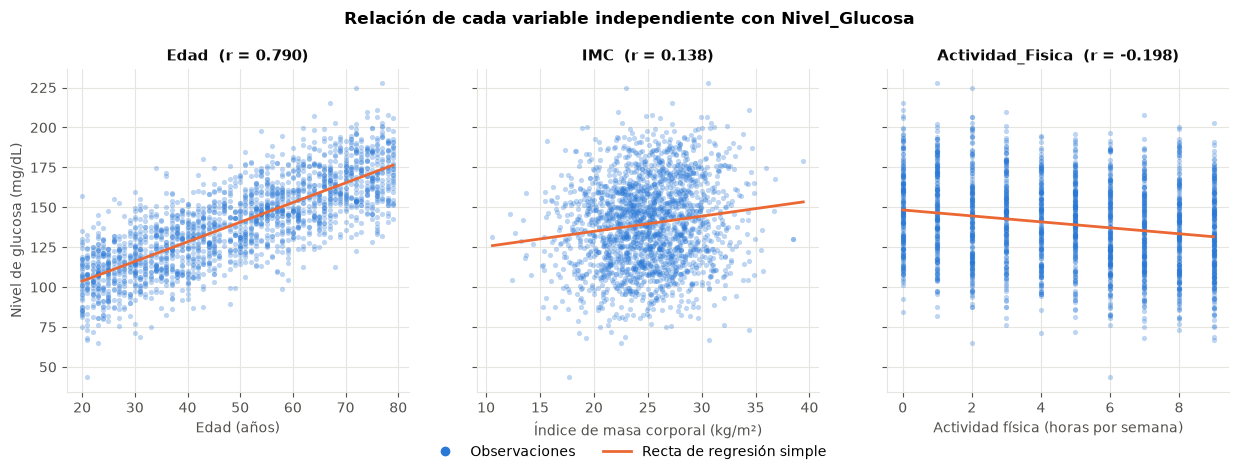

In [9]:
alfa = max(0.15, min(0.7, 600 / len(df)))
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(15, 4.2), sharey=True)
for ax, var in zip(ejes, VARIABLES):
    ax.scatter(df[var], df[OBJETIVO], s=14, color=AZUL, alpha=alfa, linewidths=0)
    pendiente, corte = np.polyfit(df[var], df[OBJETIVO], 1)
    xs = np.linspace(df[var].min(), df[var].max(), 100)
    ax.plot(xs, pendiente * xs + corte, color=NARANJA, linewidth=2)
    ax.set_title(f"{var}  (r = {df[var].corr(df[OBJETIVO]):.3f})")
    ax.set_xlabel(ETIQUETAS[var])
ejes[0].set_ylabel(ETIQUETAS[OBJETIVO])
fig.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=AZUL, label="Observaciones"),
    Line2D([], [], color=NARANJA, linewidth=2, label="Recta de regresión simple"),
], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Relación de cada variable independiente con {OBJETIVO}", fontweight="bold", y=1.02)
guardar(fig, "dispersion")
plt.show()

**Lectura de las gráficas de dispersión.** La línea naranja de cada panel es una regresión *simple* (una sola variable).

- **Edad:** tendencia ascendente clara; a mayor edad, mayor glucosa.
- **IMC:** pendiente positiva suave, con mucha dispersión.
- **Actividad_Fisica:** pendiente negativa; la glucosa baja a medida que aumentan las horas de ejercicio. Los puntos forman columnas porque la variable toma valores enteros.

## 3. Preparación de los datos

- **Limpieza:** se eliminan nulos y duplicados. En este dataset no hay ninguno, pero el paso se deja en el código para que el proceso sea reproducible con datos nuevos.
- **Atípicos:** se conservan, por las razones explicadas en la sección 2.3.
- **Escalado:** no es necesario. La regresión lineal por mínimos cuadrados da las mismas predicciones con o sin escalar, y sin escalar los coeficientes quedan en las unidades originales, lo que facilita interpretarlos.
- **División:** 80 % para entrenamiento y 20 % para prueba, con `random_state=42` para que el resultado sea reproducible.

In [10]:
# Limpieza: se eliminan nulos y duplicados (si los hubiera) y se verifica el resultado
filas_antes = len(df)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {filas_antes} | filas después de la limpieza: {len(df)}")

X = df[VARIABLES]
y = df[OBJETIVO]

# División 80 % entrenamiento / 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Filas antes: 2000 | filas después de la limpieza: 2000
Entrenamiento: (1600, 3) | Prueba: (400, 3)


## 4. Modelado

Se ajusta un modelo de **regresión lineal múltiple** con `LinearRegression` de scikit-learn, usando solo los datos de entrenamiento. El modelo busca la ecuación

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3$$

que minimiza la suma de los errores al cuadrado (mínimos cuadrados ordinarios).

In [11]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

coeficientes = pd.Series(modelo.coef_, index=VARIABLES, name="Coeficiente")
print(f"Intercepto: {modelo.intercept_:,.4f}")
display(coeficientes.to_frame())

ecuacion = f"{OBJETIVO} = {modelo.intercept_:.4f}" + "".join(
    f" {'+' if c >= 0 else '-'} {abs(c):.4f}*{v}" for v, c in coeficientes.items())
print("Ecuación del modelo:")
print(ecuacion)

Intercepto: 65.8609


,Coeficiente
Edad,1.2266
IMC,0.9334
Actividad_Fisica,-2.0853


Ecuación del modelo:
Nivel_Glucosa = 65.8609 + 1.2266*Edad + 0.9334*IMC - 2.0853*Actividad_Fisica


## 5. Evaluación

### 5.1 Métricas de desempeño

- **MSE** (error cuadrático medio): promedio de los errores al cuadrado. Cuanto más bajo, mejor.
- **RMSE**: raíz del MSE; queda en las mismas unidades de la variable dependiente.
- **R²** (coeficiente de determinación): proporción de la variación de la variable dependiente que explica el modelo (1 = ajuste perfecto).

Se calculan en entrenamiento y en prueba para detectar un posible sobreajuste.

In [12]:
def calcular_metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}


pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
metricas = {
    "entrenamiento": calcular_metricas(y_train, pred_train),
    "prueba": calcular_metricas(y_test, pred_test),
}
tabla_metricas = pd.DataFrame(metricas).T
print(f"Media de {OBJETIVO}: {y.mean():,.2f} {UNIDAD_Y}")
print(f"RMSE de prueba como % de la media: {100 * metricas['prueba']['RMSE'] / y.mean():.2f} %")
tabla_metricas

Media de Nivel_Glucosa: 139.63 mg/dL
RMSE de prueba como % de la media: 10.95 %


,MSE,RMSE,R2
entrenamiento,235.5137,15.3465,0.6862
prueba,233.6930,15.2870,0.6814


**Interpretación del desempeño**

| Conjunto | MSE | RMSE | R² |
|---|---|---|---|
| Entrenamiento | 235.51 | 15.35 | 0.6862 |
| Prueba | 233.69 | 15.29 | 0.6814 |

- **R² = 0.6814 en prueba:** el modelo explica el 68 % de la variación de la glucosa. El 32 % restante depende de factores que no están en los datos (alimentación, genética, medicamentos, etc.).
- **MSE = 233.69 (mg/dL)²**, que equivale a un **RMSE de 15.29 mg/dL**: en promedio la predicción se aleja unos 15 mg/dL del valor real (cerca del 11 % de la media, 139.6 mg/dL).
- Entrenamiento y prueba dan casi lo mismo: **no hay sobreajuste**. Es un modelo útil para entender tendencias, pero no lo bastante preciso para un diagnóstico individual.

### 5.2 Significancia estadística (p-valores)

scikit-learn no calcula p-valores, así que se ajusta el mismo modelo con `statsmodels`. El **p-valor** de un coeficiente indica si su efecto se distingue de cero: si es menor a 0.05 la variable es estadísticamente significativa.

In [13]:
# El mismo modelo ajustado con statsmodels para obtener p-valores e intervalos de confianza
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:          Nivel_Glucosa   R-squared:                       0.686
Model:                            OLS   Adj. R-squared:                  0.686
Method:                 Least Squares   F-statistic:                     1163.
Date:                Thu, 01 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:58:39   Log-Likelihood:                -6639.7
No. Observations:                1600   AIC:                         1.329e+04
Df Residuals:                    1596   BIC:                         1.331e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const               65.8609      2.701  

### 5.3 Coeficientes, p-valores e importancia de las variables

In [14]:
# Coeficiente estandarizado (beta) = coeficiente * desviación estándar de X / desviación estándar de y.
# Al quedar todas las variables en la misma escala, permite comparar su importancia.
ic = ols.conf_int()
betas = coeficientes * X_train.std() / y_train.std()
tabla_coef = pd.DataFrame({
    "Coeficiente": coeficientes,
    "Error estándar": ols.bse[VARIABLES],
    "p-valor": ols.pvalues[VARIABLES],
    "IC 95% inf": ic.loc[VARIABLES, 0],
    "IC 95% sup": ic.loc[VARIABLES, 1],
    "Coef. estandarizado": betas,
    "Efecto de 1 desv. estándar": coeficientes * X_train.std(),
    "Significativa (5%)": np.where(ols.pvalues[VARIABLES] < 0.05, "Sí", "No"),
})
# statsmodels y scikit-learn deben dar los mismos coeficientes
assert np.allclose(ols.params[VARIABLES], modelo.coef_) and np.isclose(ols.params["const"], modelo.intercept_)
print(f"p-valor del intercepto: {ols.pvalues['const']:.3g}")
tabla_coef.style.format({"p-valor": "{:.3g}", "Coeficiente": "{:,.4f}", "Error estándar": "{:,.4f}",
                        "IC 95% inf": "{:,.4f}", "IC 95% sup": "{:,.4f}",
                        "Coef. estandarizado": "{:.4f}", "Efecto de 1 desv. estándar": "{:,.3f}"})

p-valor del intercepto: 6.69e-112


,Coeficiente,Error estándar,p-valor,IC 95% inf,IC 95% sup,Coef. estandarizado,Efecto de 1 desv. estándar,Significativa (5%)
Edad,1.2266,0.0218,0,1.1837,1.2694,0.7874,21.578,Sí
IMC,0.9334,0.0963,1.31e-21,0.7444,1.1223,0.1359,3.724,Sí
Actividad_Fisica,-2.0853,0.1312,6.52e-53,-2.3426,-1.8279,-0.2229,-6.108,Sí


Figura guardada: informe/figuras/glucosa_importancia.png


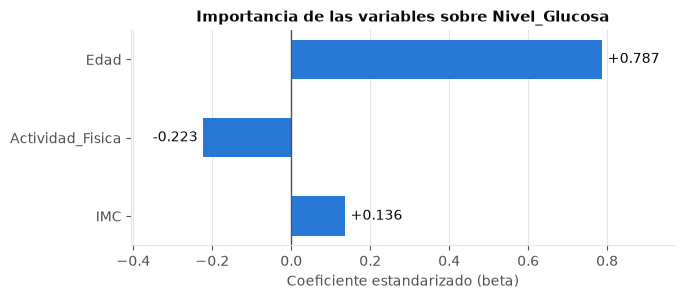

Variable de mayor impacto: Edad


In [15]:
orden = betas.abs().sort_values().index
fig, ax = plt.subplots(figsize=(7, 2.8))
barras = ax.barh(orden, betas[orden], color=AZUL, height=0.5)
ax.bar_label(barras, labels=[f"{v:+.3f}" for v in betas[orden]], padding=4, color=TEXTO)
ax.axvline(0, color=TEXTO_SEC, linewidth=1)
ax.margins(x=0.18)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente estandarizado (beta)")
ax.set_title(f"Importancia de las variables sobre {OBJETIVO}")
guardar(fig, "importancia")
plt.show()

print("Variable de mayor impacto:", betas.abs().idxmax())

In [16]:
# Interpretación automática a partir de los resultados obtenidos
UNIDADES_X = {'Edad': 'año de edad', 'IMC': 'punto de IMC', 'Actividad_Fisica': 'hora semanal de ejercicio'}
for var in VARIABLES:
    c, p = coeficientes[var], ols.pvalues[var]
    sentido = "aumenta" if c > 0 else "disminuye"
    conclusion = "es estadísticamente significativa" if p < 0.05 else "NO es estadísticamente significativa"
    print(f"- {var}: por cada {UNIDADES_X[var]} adicional, {OBJETIVO} {sentido} en promedio "
          f"{abs(c):,.4f} {UNIDAD_Y}, manteniendo constantes las demás variables. "
          f"p-valor {fmt_p(p)}: {conclusion} al 5 %.")

- Edad: por cada año de edad adicional, Nivel_Glucosa aumenta en promedio 1.2266 mg/dL, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.
- IMC: por cada punto de IMC adicional, Nivel_Glucosa aumenta en promedio 0.9334 mg/dL, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.
- Actividad_Fisica: por cada hora semanal de ejercicio adicional, Nivel_Glucosa disminuye en promedio 2.0853 mg/dL, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.


**Interpretación de los coeficientes**

Ecuación: `Nivel_Glucosa = 65.86 + 1.227·Edad + 0.933·IMC − 2.085·Actividad_Fisica`

- **Intercepto (65.86):** valor base de la ecuación cuando las tres variables valen cero; no tiene interpretación práctica (no hay pacientes con edad o IMC cero).
- **Edad (+1.227, p < 0.001):** cada año adicional de edad se asocia con **1.23 mg/dL más** de glucosa, con el IMC y la actividad física constantes.
- **IMC (+0.933, p < 0.001):** cada punto adicional de IMC se asocia con **0.93 mg/dL más** de glucosa.
- **Actividad_Fisica (−2.085, p < 0.001):** cada hora semanal adicional de ejercicio se asocia con **2.09 mg/dL menos** de glucosa. Es el único factor protector del modelo.

Las tres variables son **estadísticamente significativas** (p-valores muy inferiores a 0.05).

**Importancia de cada variable (coeficientes estandarizados)**

| Variable | Coef. estandarizado | Efecto de 1 desviación estándar |
|---|---|---|
| `Edad` | **0.787** | +21.6 mg/dL |
| `Actividad_Fisica` | −0.223 | −6.1 mg/dL |
| `IMC` | 0.136 | +3.7 mg/dL |

No se pueden comparar directamente los coeficientes originales porque cada variable tiene una escala distinta (la edad varía decenas de años; la actividad, pocas horas). El coeficiente estandarizado elimina ese problema.

### ¿Qué variable tiene mayor impacto en el nivel de glucosa?

**La `Edad`.** Su coeficiente estandarizado (0.787) es unas 3.5 veces el de la actividad física (0.223 en valor absoluto) y casi 6 veces el del IMC (0.136). Además es la de mayor correlación con la glucosa (0.790).

Un matiz importante: *por unidad*, la actividad física tiene el coeficiente más grande (−2.09 mg/dL por hora frente a +1.23 por año), pero la edad varía mucho más entre pacientes (desviación estándar de unos 17.5 años frente a 2.9 horas), y por eso explica mucho más las diferencias de glucosa. La actividad física es la segunda en importancia y la única que la persona puede modificar.

### 5.4 Valores reales vs. predichos

Figura guardada: informe/figuras/glucosa_real_vs_predicho.png


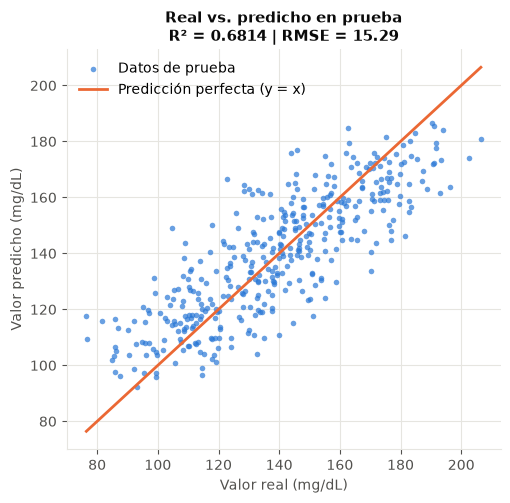

In [17]:
alfa_test = max(0.2, min(0.7, 300 / len(y_test)))
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(y_test, pred_test, s=16, color=AZUL, alpha=alfa_test, linewidths=0, label="Datos de prueba")
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax.plot(limites, limites, color=NARANJA, linewidth=2, label="Predicción perfecta (y = x)")
ax.set_xlabel(f"Valor real ({UNIDAD_Y})")
ax.set_ylabel(f"Valor predicho ({UNIDAD_Y})")
ax.set_title(f"Real vs. predicho en prueba\nR² = {metricas['prueba']['R2']:.4f} | RMSE = {metricas['prueba']['RMSE']:.2f}")
ax.legend(loc="upper left")
guardar(fig, "real_vs_predicho")
plt.show()

### 5.5 Análisis de residuos

Figura guardada: informe/figuras/glucosa_residuos.png


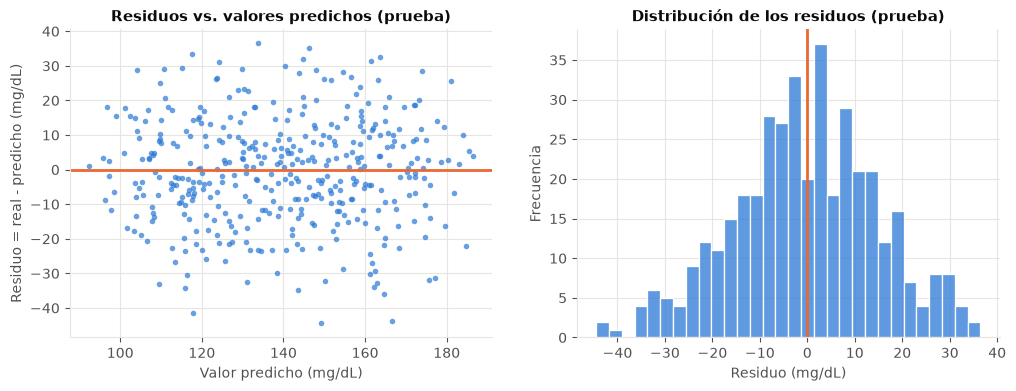

Media de los residuos: -0.498 | Desviación estándar: 15.298


In [18]:
residuos = y_test - pred_test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(pred_test, residuos, s=16, color=AZUL, alpha=alfa_test, linewidths=0)
ax1.axhline(0, color=NARANJA, linewidth=2)
ax1.set_xlabel(f"Valor predicho ({UNIDAD_Y})")
ax1.set_ylabel(f"Residuo = real - predicho ({UNIDAD_Y})")
ax1.set_title("Residuos vs. valores predichos (prueba)")
sns.histplot(residuos, bins=30, color=AZUL, edgecolor="white", ax=ax2)
ax2.axvline(0, color=NARANJA, linewidth=2)
ax2.set_xlabel(f"Residuo ({UNIDAD_Y})")
ax2.set_ylabel("Frecuencia")
ax2.set_title("Distribución de los residuos (prueba)")
guardar(fig, "residuos")
plt.show()

print(f"Media de los residuos: {residuos.mean():.3f} | Desviación estándar: {residuos.std():.3f}")

**Lectura de las gráficas de evaluación**

- En *real vs. predicho* los puntos siguen la diagonal pero con una nube ancha, coherente con un R² de 0.68.
- Los residuos se distribuyen alrededor de cero sin patrón visible y su histograma es aproximadamente simétrico: el modelo lineal es razonable y no se observa un sesgo sistemático.

## 6. Despliegue: exportación del modelo

El modelo entrenado se guarda en disco para usarlo después en la interfaz web sin volver a entrenar. Se exporta en dos formatos:

- **`.pkl` (pickle):** módulo estándar de Python para serializar cualquier objeto.
- **`.joblib` (joblib):** librería recomendada por scikit-learn; es más eficiente con objetos que contienen arreglos grandes de NumPy.

Junto con el modelo se guardan los nombres de las variables, las métricas y los rangos de los datos, que la aplicación usa para validar las entradas.

In [19]:
paquete = {
    "modelo": modelo,
    "ejercicio": "Glucosa",
    "variables": VARIABLES,
    "objetivo": OBJETIVO,
    "unidad_objetivo": UNIDAD_Y,
    "etiquetas": ETIQUETAS,
    "intercepto": float(modelo.intercept_),
    "coeficientes": {v: float(c) for v, c in coeficientes.items()},
    "coef_estandarizados": {v: float(b) for v, b in betas.items()},
    "p_valores": {v: float(ols.pvalues[v]) for v in VARIABLES},
    "ic95": {v: [float(ic.loc[v, 0]), float(ic.loc[v, 1])] for v in VARIABLES},
    "ecuacion": ecuacion,
    "metricas": {k: {m: float(x) for m, x in d.items()} for k, d in metricas.items()},
    "rangos": {c: {"min": float(df[c].min()), "max": float(df[c].max()), "media": float(df[c].mean())}
               for c in df.columns},
    "limites_validos": {'Edad': [0, 120], 'IMC': [5, 80], 'Actividad_Fisica': [0, 168]},
    "variables_enteras": [],
    "n_entrenamiento": len(X_train),
    "n_prueba": len(X_test),
    "random_state": SEMILLA,
    "version_sklearn": sklearn.__version__,
}

ruta_joblib = MODELOS / f"modelo_{NOMBRE}.joblib"
ruta_pkl = MODELOS / f"modelo_{NOMBRE}.pkl"

joblib.dump(paquete, ruta_joblib)              # joblib
with open(ruta_pkl, "wb") as f:                # pickle
    pickle.dump(paquete, f)

# Metadatos legibles (sin el modelo) para el informe
metadatos = {k: v for k, v in paquete.items() if k != "modelo"}
metadatos["correlaciones_objetivo"] = {v: float(corr.loc[v, OBJETIVO]) for v in VARIABLES}
metadatos["atipicos_iqr"] = {c: int(n) for c, n in atipicos.items()}
metadatos["extra"] = {}
with open(MODELOS / f"metadatos_{NOMBRE}.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)

# Comprobación: los modelos cargados predicen igual que el original
cargado_joblib = joblib.load(ruta_joblib)
with open(ruta_pkl, "rb") as f:
    cargado_pkl = pickle.load(f)
assert np.allclose(cargado_joblib["modelo"].predict(X_test), pred_test)
assert np.allclose(cargado_pkl["modelo"].predict(X_test), pred_test)
print("Modelos guardados y verificados:")
for ruta in (ruta_joblib, ruta_pkl):
    print(f"  {ruta.relative_to(BASE)}  ({ruta.stat().st_size} bytes)")

Modelos guardados y verificados:
  modelos/modelo_glucosa.joblib  (2126 bytes)
  modelos/modelo_glucosa.pkl  (1844 bytes)


In [20]:
# Ejemplo de uso del modelo cargado con valores nuevos
ejemplo = pd.DataFrame([{'Edad': 50, 'IMC': 25.0, 'Actividad_Fisica': 5}])
prediccion = cargado_joblib["modelo"].predict(ejemplo[cargado_joblib["variables"]])[0]
print("Entrada:", ejemplo.to_dict("records")[0])
print(f"Predicción de {OBJETIVO}: {prediccion:,.2f} {UNIDAD_Y}")

Entrada: {'Edad': 50, 'IMC': 25.0, 'Actividad_Fisica': 5}
Predicción de Nivel_Glucosa: 140.10 mg/dL


## 7. Conclusiones del ejercicio

1. El modelo explica el **68 % de la variación de la glucosa** (R² = 0.6814 en prueba) con **MSE = 233.69** y RMSE = 15.29 mg/dL.
2. Las tres variables son significativas (p < 0.001): la glucosa **aumenta con la edad** (+1.23 mg/dL por año) y **con el IMC** (+0.93 por punto) y **disminuye con la actividad física** (−2.09 por hora semanal).
3. **La variable de mayor impacto es la `Edad`** (coeficiente estandarizado 0.787), seguida de `Actividad_Fisica` (−0.223) e `IMC` (0.136).
4. No hay sobreajuste. El error de unos 15 mg/dL indica que hay otros factores no medidos que también influyen.
5. **Limitación:** el modelo muestra asociaciones, no causas, y no reemplaza una valoración médica.